<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/Aidl_lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

        WINE QUALITY DATASET

First 5 rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4      

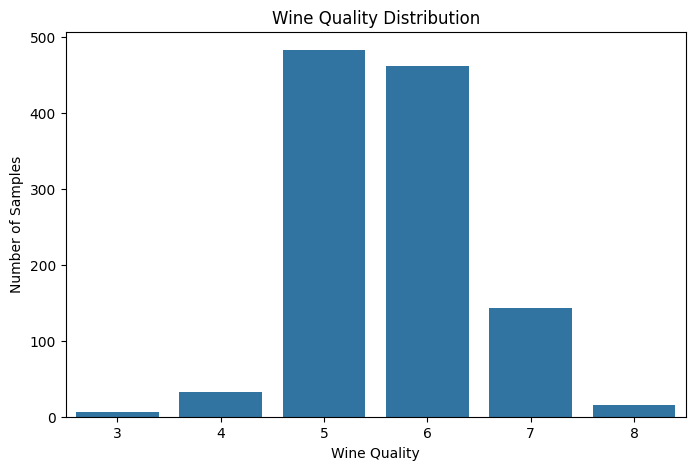


Input Features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Number of Input Features:
11

Target Classes:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

Original Classes:
[3 4 5 6 7 8]

Encoded Classes:
[0 1 2 3 4 5]

Training Samples: 914
Testing Samples: 229

             ANN MODEL
WineQualityANN(
  (layer1): Linear(in_features=11, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=6, bias=True)
  (relu): ReLU()
)

             TRAINING
Epoch [ 10/100] Train Loss: 0.9140 | Test Loss: 0.9257 | Test Accuracy: 0.6507
Epoch [ 20/100] Train Loss: 0.8340 | Test Loss: 0.9178 | Test Accuracy: 0.6114
Epoch [ 30/100] Train Loss: 0.7801 | Test Loss: 0.9274 | Test Accuracy: 0.6463
Epoch [ 40/100] Train Loss: 0.7362 | Test Loss: 0.9417 | Test A

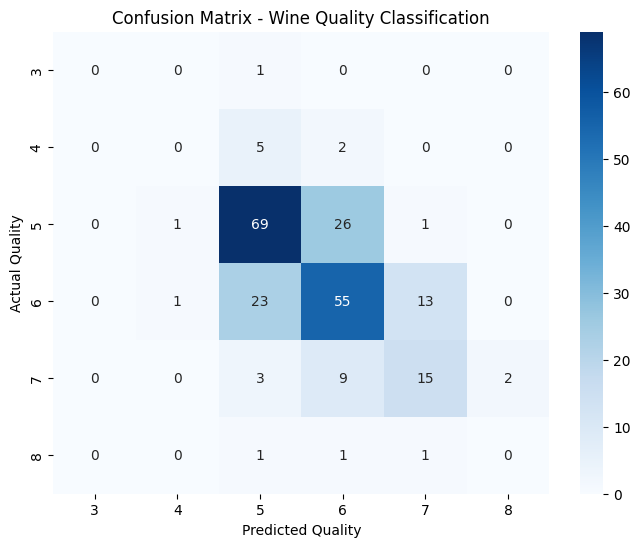

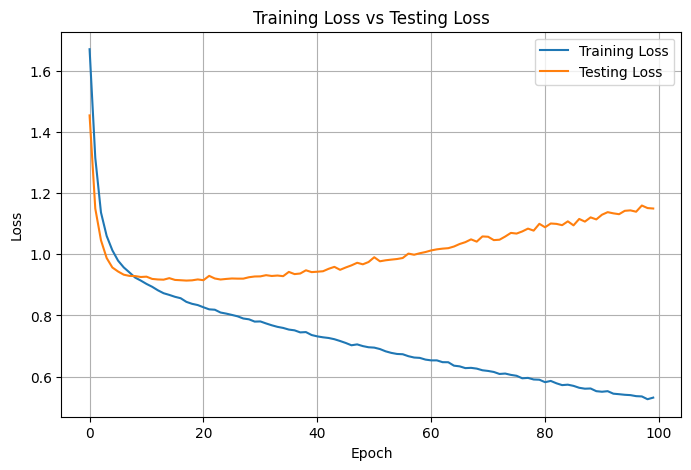

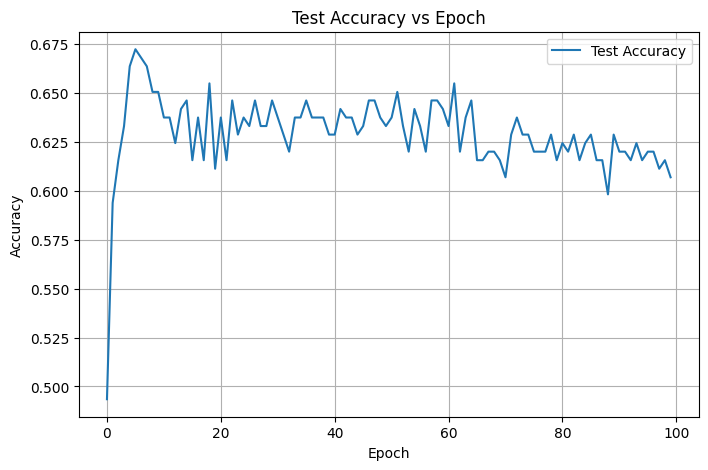

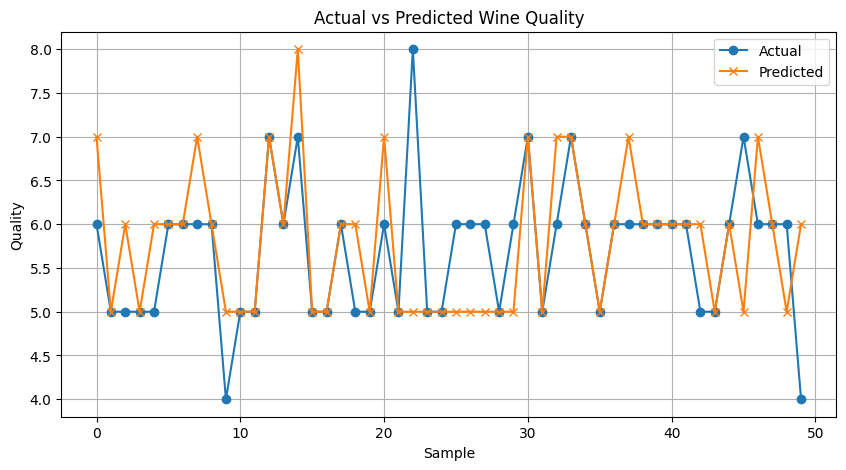


          SAMPLE PREDICTIONS
Sample 1: Actual = 6, Predicted = 7
Sample 2: Actual = 5, Predicted = 5
Sample 3: Actual = 5, Predicted = 6
Sample 4: Actual = 5, Predicted = 5
Sample 5: Actual = 5, Predicted = 6
Sample 6: Actual = 6, Predicted = 6
Sample 7: Actual = 6, Predicted = 6
Sample 8: Actual = 6, Predicted = 7
Sample 9: Actual = 6, Predicted = 6
Sample 10: Actual = 4, Predicted = 5

        SAMPLE SOFTMAX PROBABILITIES

Sample 1
Actual Quality: 6
Predicted Quality: 7
Probabilities: [7.5918681e-12 3.5356807e-05 1.1488241e-03 2.6976582e-01 6.8103439e-01
 4.8015594e-02]

Sample 2
Actual Quality: 5
Predicted Quality: 5
Probabilities: [8.9646690e-02 7.5156003e-02 7.8178298e-01 5.3395830e-02 1.8416386e-05
 1.5851141e-08]

Sample 3
Actual Quality: 5
Predicted Quality: 6
Probabilities: [5.4271917e-05 4.1648448e-03 1.5033945e-01 8.4455502e-01 8.8629086e-04
 9.5225325e-08]

Sample 4
Actual Quality: 5
Predicted Quality: 5
Probabilities: [4.7756948e-10 1.5028146e-03 9.8071182e-01 1.6829697e-

In [ ]:
# ============================================================
# LAB/EXP 4
# IMPLEMENTING AN ANN FOR MULTI-CLASS CLASSIFICATION
# WINE QUALITY DATASET
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# 2. SET RANDOM SEED
# ------------------------------------------------------------

np.random.seed(42)
torch.manual_seed(42)


# ------------------------------------------------------------
# 3. LOAD DATASET
# ------------------------------------------------------------

file_path = "/mnt/data/WineQT(1).csv"

df = pd.read_csv("/content/WineQT.csv")


# Clean column names
df.columns = df.columns.str.strip()


print("==========================================")
print("        WINE QUALITY DATASET")
print("==========================================")

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 4. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\nMissing Values:")
print(df.isnull().sum())


# ------------------------------------------------------------
# 5. CHECK TARGET COLUMN
# ------------------------------------------------------------

if "quality" not in df.columns:
    raise ValueError(
        "The 'quality' column was not found. "
        "Available columns are: "
        + str(df.columns.tolist())
    )


# ------------------------------------------------------------
# 6. DISPLAY WINE QUALITY DISTRIBUTION
# ------------------------------------------------------------

print("\nWine Quality Distribution:")
print(df["quality"].value_counts().sort_index())


# ------------------------------------------------------------
# 7. VISUALIZE QUALITY DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="quality"
)

plt.title("Wine Quality Distribution")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")

plt.show()


# ------------------------------------------------------------
# 8. SEPARATE FEATURES AND TARGET
# ------------------------------------------------------------

# Remove Id because it is only an identifier
X = df.drop(
    columns=["quality", "Id"]
)

y = df["quality"]


print("\nInput Features:")
print(X.columns.tolist())

print("\nNumber of Input Features:")
print(X.shape[1])

print("\nTarget Classes:")
print(sorted(y.unique()))


# ------------------------------------------------------------
# 9. ENCODE TARGET CLASSES
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("\nOriginal Classes:")
print(label_encoder.classes_)

print("\nEncoded Classes:")
print(np.unique(y_encoded))


# ------------------------------------------------------------
# 10. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)


print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ------------------------------------------------------------
# 11. FEATURE SCALING
# ------------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


# ------------------------------------------------------------
# 12. CONVERT DATA TO PYTORCH TENSORS
# ------------------------------------------------------------

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)


# ------------------------------------------------------------
# 13. CREATE DATA LOADER
# ------------------------------------------------------------

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)


# ------------------------------------------------------------
# 14. BUILD ANN MODEL
# ------------------------------------------------------------

class WineQualityANN(nn.Module):

    def __init__(self):

        super(WineQualityANN, self).__init__()

        self.layer1 = nn.Linear(11, 64)

        self.layer2 = nn.Linear(64, 32)

        self.output_layer = nn.Linear(32, 6)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.layer1(x)

        x = self.relu(x)

        x = self.layer2(x)

        x = self.relu(x)

        x = self.output_layer(x)

        return x


# Create model
model = WineQualityANN()


print("\n==========================================")
print("             ANN MODEL")
print("==========================================")

print(model)


# ------------------------------------------------------------
# 15. LOSS FUNCTION
# ------------------------------------------------------------

# CrossEntropyLoss is suitable for multi-class
# classification.

criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# 16. OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


# ------------------------------------------------------------
# 17. TRAIN THE MODEL
# ------------------------------------------------------------

epochs = 100

train_losses = []
test_losses = []
test_accuracies = []


print("\n==========================================")
print("             TRAINING")
print("==========================================")


for epoch in range(epochs):

    # -------------------------
    # Training
    # -------------------------

    model.train()

    total_loss = 0

    for batch_X, batch_y in train_loader:

        # Reset gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(batch_X)

        # Calculate loss
        loss = criterion(
            outputs,
            batch_y
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += (
            loss.item()
            * batch_X.size(0)
        )


    train_loss = (
        total_loss
        / len(train_loader.dataset)
    )

    train_losses.append(train_loss)


    # -------------------------
    # Testing
    # -------------------------

    model.eval()

    with torch.no_grad():

        test_outputs = model(
            X_test_tensor
        )

        test_loss = criterion(
            test_outputs,
            y_test_tensor
        )

        # Softmax converts logits
        # into probabilities
        probabilities = torch.softmax(
            test_outputs,
            dim=1
        )

        # Select class having
        # highest probability
        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        test_accuracy = (
            predictions == y_test_tensor
        ).float().mean().item()


    test_losses.append(
        test_loss.item()
    )

    test_accuracies.append(
        test_accuracy
    )


    # Print every 10 epochs
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1:3d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Test Accuracy: {test_accuracy:.4f}"
        )


# ------------------------------------------------------------
# 18. FINAL MODEL EVALUATION
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    outputs = model(
        X_test_tensor
    )

    # Apply Softmax
    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    # Get predicted class
    predictions = torch.argmax(
        probabilities,
        dim=1
    )


# Convert tensors to NumPy
y_pred = predictions.numpy()

y_true = y_test


# ------------------------------------------------------------
# 19. CALCULATE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)


print("\n==========================================")
print("             FINAL RESULTS")
print("==========================================")

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1 Score  : {f1:.4f}"
)


# ------------------------------------------------------------
# 20. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n==========================================")
print("       CLASSIFICATION REPORT")
print("==========================================")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(
            len(label_encoder.classes_)
        ),
        target_names=[
            str(x)
            for x in label_encoder.classes_
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 21. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        len(label_encoder.classes_)
    )
)

print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 22. CONFUSION MATRIX VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Confusion Matrix - Wine Quality Classification"
)

plt.xlabel("Predicted Quality")

plt.ylabel("Actual Quality")

plt.show()


# ------------------------------------------------------------
# 23. TRAINING AND TESTING LOSS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    test_losses,
    label="Testing Loss"
)

plt.title(
    "Training Loss vs Testing Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()


# ------------------------------------------------------------
# 24. TEST ACCURACY GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    test_accuracies,
    label="Test Accuracy"
)

plt.title(
    "Test Accuracy vs Epoch"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()


# ------------------------------------------------------------
# 25. ACTUAL VS PREDICTED
# ------------------------------------------------------------

actual_quality = label_encoder.inverse_transform(
    y_true[:50]
)

predicted_quality = label_encoder.inverse_transform(
    y_pred[:50]
)


plt.figure(figsize=(10, 5))

plt.plot(
    actual_quality,
    marker="o",
    label="Actual"
)

plt.plot(
    predicted_quality,
    marker="x",
    label="Predicted"
)

plt.title(
    "Actual vs Predicted Wine Quality"
)

plt.xlabel("Sample")

plt.ylabel("Quality")

plt.legend()

plt.grid()

plt.show()


# ------------------------------------------------------------
# 26. DISPLAY SAMPLE PREDICTIONS
# ------------------------------------------------------------

print("\n==========================================")
print("          SAMPLE PREDICTIONS")
print("==========================================")


for i in range(10):

    actual = label_encoder.inverse_transform(
        [y_true[i]]
    )[0]

    predicted = label_encoder.inverse_transform(
        [y_pred[i]]
    )[0]

    print(
        f"Sample {i+1}: "
        f"Actual = {actual}, "
        f"Predicted = {predicted}"
    )


# ------------------------------------------------------------
# 27. DISPLAY SOFTMAX PROBABILITIES
# ------------------------------------------------------------

print("\n==========================================")
print("        SAMPLE SOFTMAX PROBABILITIES")
print("==========================================")


for i in range(5):

    print(
        f"\nSample {i+1}"
    )

    print(
        "Actual Quality:",
        label_encoder.inverse_transform(
            [y_true[i]]
        )[0]
    )

    print(
        "Predicted Quality:",
        label_encoder.inverse_transform(
            [y_pred[i]]
        )[0]
    )

    print(
        "Probabilities:",
        probabilities[i].numpy()
    )


# ------------------------------------------------------------
# 28. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n==========================================")
print("              CONCLUSION")
print("==========================================")

print(
    f"""
The Wine Quality dataset was successfully
classified using a PyTorch Artificial Neural
Network.

The dataset contains 11 useful input features
after removing the Id column.

The ANN architecture is:

Input Layer  : 11 neurons
Hidden Layer : 64 neurons
Hidden Layer : 32 neurons
Output Layer : 6 neurons

ReLU activation was used in the hidden layers.

Softmax was used to convert the output logits
into probabilities for the six wine quality
classes: 3, 4, 5, 6, 7 and 8.

CrossEntropyLoss was used as the loss function
because this is a multi-class classification
problem.

Final Performance:

Accuracy  : {accuracy:.4f}
Precision : {precision:.4f}
Recall    : {recall:.4f}
F1 Score  : {f1:.4f}

The model performs better on the frequently
occurring quality classes, particularly 5 and 6.
The less frequent classes such as 3 and 8 are
more difficult to classify because the dataset
is imbalanced.
"""
)
